<a href="https://colab.research.google.com/github/DyutideeptaB/AI-for-Sinuous-Detection/blob/main/Langchain%20Basics/session_1_sap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

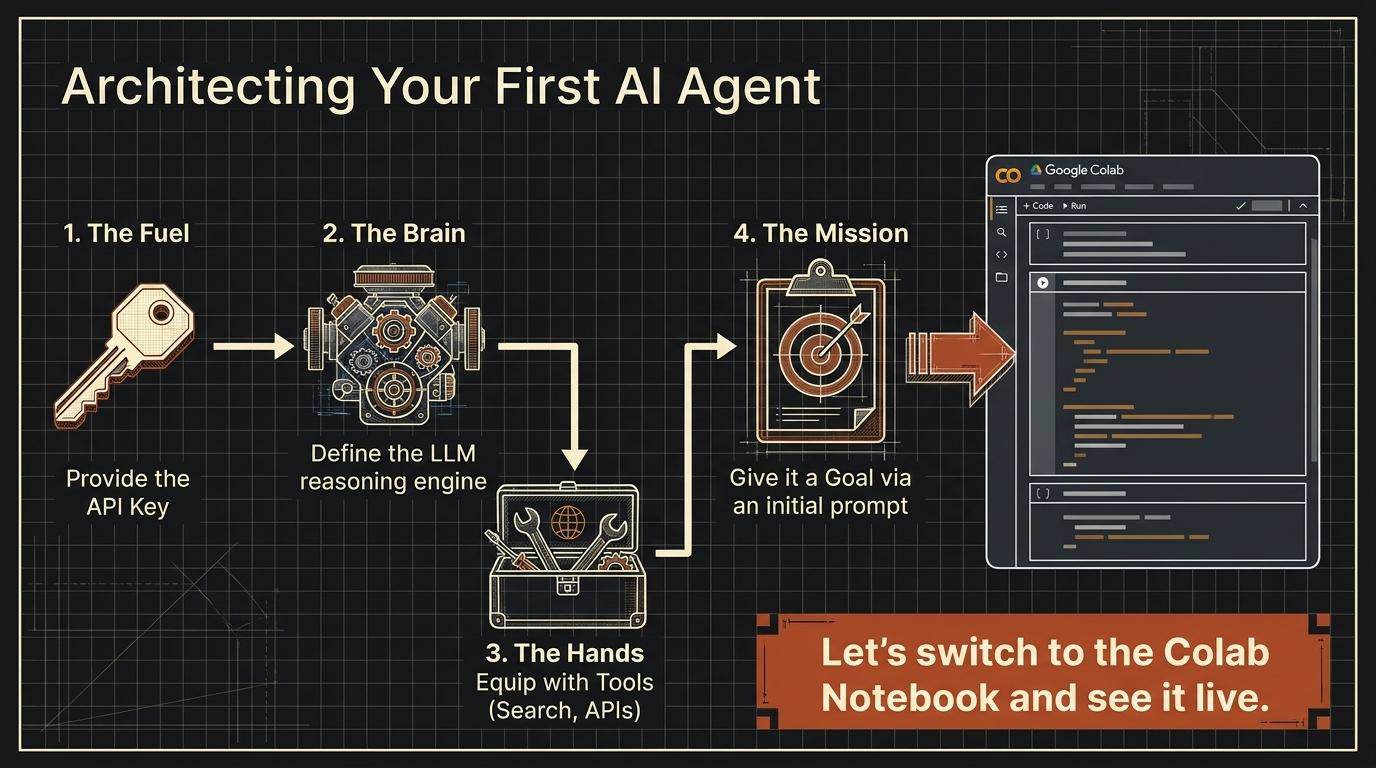

======================================================================

 LANGCHAIN CRASH COURSE — Python Basics + Agentic AI Basics (30 min)

 ** GOOGLE COLAB EDITION **

======================================================================

HOW TO USE THIS FILE IN COLAB

    Paste this whole file into a single Colab cell (or split it across
    a few cells at the "PART" boundaries) and run it top to bottom.
    Everything below is plain Python — there is no "!pip install" shell
    magic — so it behaves the same whether you run it in one cell, in
    several cells, or even as a uploaded .py file executed with
    `!python langchain_crash_course_colab.py`.

WHAT THIS FILE COVERS

    PART 0 : One-time setup (installs, Colab Secrets)

    PART 1 : A 2-minute Python warm-up (just enough to follow Part 2)

    PART 2 : LangChain basics
             2.1  Calling an OPEN-SOURCE model through an API key   (Groq)
             2.3  Prompt templates + chains (LCEL)
             2.4  Memory (manual buffer + automatic RunnableWithMessageHistory)
             2.5  Tools (plain Python functions the model can call)
             2.6  A simple tool-using agent
             
    PART 3 : Where to go next (not covered today)

This file is deliberately NOT a RAG (Retrieval-Augmented Generation) demo —
that is a separate topic for another session.

----------------------------------------------------------------------
PART 0 — ONE-TIME SETUP (Google Colab)
----------------------------------------------------------------------

1) PACKAGES
   The install step a few lines below (`subprocess.run([... "pip", "install" ...])`)
   installs everything this file needs the first time you run the cell.
   You don't need to run anything separately — just run this file.

2) OPEN-SOURCE MODEL VIA API KEY  ->  Groq
   Groq hosts well-known OPEN-SOURCE / open-weight models (Llama, Gemma, Qwen...)
   on very fast hardware, with a generous free tier. Steps:

       a. Go to            https://console.groq.com
       b. Sign in with Google / GitHub (free account)
       c. Open             https://console.groq.com/keys
       d. Click "Create API Key" and copy the key shown
       e. In THIS Colab notebook, click the 🔑 key icon in the LEFT sidebar
          (it's labelled "Secrets")
       f. Click "+ Add new secret":
                Name  :  GROQ_API_KEY
                Value :  paste the key you copied in step (d)
       g. Toggle "Notebook access" ON for this notebook

   That's it — the key never has to be typed into this file. The code
   below reads it securely with `userdata.get("GROQ_API_KEY")`.

   Full list of available Groq model names: https://console.groq.com/docs/models
----------------------------------------------------------------------

In [1]:
import os
import sys
import subprocess

----------------------------------------------------------------------
Install the packages this file needs (first run only; quick on reruns).
Using subprocess + sys.executable instead of "!pip install" keeps this
file valid, runnable Python with or without a notebook kernel.
----------------------------------------------------------------------

In [2]:
REQUIRED_PACKAGES = ["langchain", "langchain-core", "langchain-groq"]
print("Installing required packages (first run only)...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *REQUIRED_PACKAGES], check=True)

Installing required packages (first run only)...


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'langchain', 'langchain-core', 'langchain-groq'], returncode=0)

----------------------------------------------------------------------
LangChain imports used throughout this file
----------------------------------------------------------------------

In [3]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.output_parsers import StrOutputParser
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory

from langchain.tools import tool
from langchain.agents import create_agent

from langchain_groq import ChatGroq       # open-source model via API key

from google.colab import userdata

----------------------------------------------------------------------
Read the Groq key from Colab's Secrets Manager (see PART 0, step 2 above)
----------------------------------------------------------------------

In [4]:
try:
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
    os.environ["GROQ_API_KEY"] = GROQ_API_KEY  # some libraries look for it here too
    print("GROQ_API_KEY loaded from Colab secrets.")
except Exception:
    GROQ_API_KEY = None
    print("Could not read GROQ_API_KEY from Colab secrets.")
    print("   -> Add it via the 🔑 Secrets panel on the left — see PART 0, step 2.")

GROQ_API_KEY loaded from Colab secrets.


======================================================================
PART 1 — PYTHON WARM-UP
======================================================================
Just enough Python to follow Part 2 comfortably. Everything here maps
directly onto a LangChain concept you will see in a minute:
dict/list  -> how prompts & tool arguments are shaped
function   -> exactly what a LangChain "tool" is under the hood
class      -> how an agent stores its internal state / memory
try/except -> how a well-behaved tool should fail (never crash the agent)
----------------------------------------------------------------------

In [ ]:
def python_warm_up():
    print("\n" + "=" * 70)
    print("PART 1 — PYTHON WARM-UP")
    print("=" * 70)

    # ---- Variables & basic types ----
    topic = "LangChain"            # str
    session_minutes = 30           # int
    is_hands_on = True             # bool
    print(f"Topic: {topic} | Duration: {session_minutes} min | Hands-on: {is_hands_on}")

    # ---- Lists & dictionaries ----
    # A dict is exactly the shape LangChain expects when you call a chain,
    # e.g. chain.invoke({"topic": "...", "tone": "..."})
    attendees = ["Asha", "Rohit", "Rohan"]
    session_info = {"topic": topic, "level": "beginner", "attendees": len(attendees)}
    print("Attendees:", attendees)
    print("Session info:", session_info)

    # ---- Functions ----
    # A "tool" in LangChain/agentic AI is simply a Python function like this,
    # wrapped with a bit of metadata (name, description, type hints) so the
    # model knows when and how to call it. We'll do that officially in 2.5.
    def greet(name: str) -> str:
        """Return a friendly greeting for `name`."""
        return f"Hi {name}, welcome to the workshop!"

    for person in attendees:
        print(greet(person))

    # ---- A small class ----
    # Agents use classes like this to hold conversation state: messages seen
    # so far, tool results, long-term memory, etc.
    class Attendee:
        def __init__(self, name: str, has_laptop: bool = True):
            self.name = name
            self.has_laptop = has_laptop

        def status(self) -> str:
            ready = "ready" if self.has_laptop else "not ready"
            return f"{self.name} is {ready} for the hands-on part."

    print(Attendee("Asha").status())

    # ---- try / except ----
    # Tools WILL fail sometimes (bad input, timeouts, divide-by-zero...).
    # A good tool catches the error and returns a readable message instead
    # of letting the exception crash the whole agent loop.
    def safe_divide(a: float, b: float):
        try:
            return a / b
        except ZeroDivisionError:
            return "Error: cannot divide by zero."

    print("10 / 2 =", safe_divide(10, 2))
    print("10 / 0 =", safe_divide(10, 0))


python_warm_up()


PART 1 — PYTHON WARM-UP
Topic: LangChain | Duration: 30 min | Hands-on: True
Attendees: ['Asha', 'Rohit', 'Rohan']
Session info: {'topic': 'LangChain', 'level': 'beginner', 'attendees': 3}
Hi Asha, welcome to the workshop!
Hi Rohit, welcome to the workshop!
Hi Rohan, welcome to the workshop!
Asha is ready for the hands-on part.
10 / 2 = 5.0
10 / 0 = Error: cannot divide by zero.


======================================================================
PART 2 — LANGCHAIN BASICS
======================================================================

----------------------------------------------------------------------
2.1  Open-source model called through an API key (Groq)
----------------------------------------------------------------------

In [ ]:
# ----------------------------------------------------------------------
# 2.1  Open-source model called through an API key (Groq)
# ----------------------------------------------------------------------
def demo_groq_llm():
    print("\n" + "=" * 70)
    print("2.1 — Open-source model via API key (Groq)")
    print("=" * 70)

    if not GROQ_API_KEY:
        print("Skipped: no GROQ_API_KEY found in Colab secrets (see PART 0, step 2).")
        return None

    # "openai/gpt-oss-20b" is an OPEN-SOURCE (open-weight) model that OpenAI
    # released publicly — Groq just hosts it for us and serves it very fast.
    # (Note: Groq deprecated "llama-3.1-8b-instant" on 16 Aug 2026 and lists
    # this as its recommended replacement — see console.groq.com/docs/deprecations
    # if you ever hit a "model_not_found" 404 again, that page always has the
    # current answer.)
    llm = ChatGroq(
        model="openai/gpt-oss-20b",
        api_key=GROQ_API_KEY,
        temperature=0.7,   # 0 = focused/deterministic, 1 = more creative
    )

    response = llm.invoke("In one short sentence, what is LangChain?")
    print("Groq (GPT-OSS 20B) ->", response.content)
    return llm


# This `llm` is reused by the model-dependent demos below (2.3, 2.4b, 2.6).
llm = demo_groq_llm()


2.1 — Open-source model via API key (Groq)
Groq (GPT-OSS 20B) -> LangChain is an open‑source framework that lets developers build applications powered by large language models.


----------------------------------------------------------------------
2.3  Prompt templates + chains (LCEL: the `|` pipe syntax)
----------------------------------------------------------------------

In [ ]:
# ----------------------------------------------------------------------
# 2.3  Prompt templates + chains (LCEL: the `|` pipe syntax)
# ----------------------------------------------------------------------
def demo_prompt_and_chain(llm):
    print("\n" + "=" * 70)
    print("2.3 — Prompt templates + chains")
    print("=" * 70)

    # A PromptTemplate has "blanks" ({tone}, {topic}) that get filled in at
    # call time, the same way an f-string does — but it also knows how to
    # format itself correctly for a chat model.
    prompt = ChatPromptTemplate.from_template(
        "Tell me one short, {tone} fact about {topic}."
    )
    parser = StrOutputParser()  # turns the model's raw reply into a plain string

    # The pipe `|` operator wires these pieces together left to right:
    # prompt (fills the template) -> llm (generates a reply) -> parser (cleans it up)
    chain = prompt | llm | parser

    result = chain.invoke({"tone": "fun", "topic": "octopuses"})
    print("Chain result ->", result)

    # Example 2: chaining two steps together — the output of one feeds the next
    writer_prompt = ChatPromptTemplate.from_template("Write one sentence about {place}.")
    critic_prompt = ChatPromptTemplate.from_template("Give a one-line review of: {sentence}")

    writer_chain = writer_prompt | llm | parser
    critic_chain = {"sentence": writer_chain} | critic_prompt | llm | parser

    review = critic_chain.invoke({"place": "the Amazon rainforest"})
    print("Two-step chain result ->", review)


demo_prompt_and_chain(llm)


2.3 — Prompt templates + chains
Chain result -> Octopuses can squeeze through any opening that fits their soft body—no bones to get stuck!
Two-step chain result -> A breathtaking, biodiverse jewel that anchors Earth’s climate, the Amazon rainforest spans nine nations and yet faces an uncertain future.


----------------------------------------------------------------------
2.4  Memory — "contextual buffer memory and stuffs"
----------------------------------------------------------------------

In [ ]:
# ----------------------------------------------------------------------
# 2.4a  Memory concept: a manual conversation buffer (no LangChain code)
# ----------------------------------------------------------------------
def demo_manual_buffer_memory():
    """
    2.4a — The IDEA behind memory, with no LangChain code at all.
    A "conversation buffer" is really just a growing list of past messages
    that gets replayed back to the model on every turn so it has context.
    """
    print("\n" + "=" * 70)
    print("2.4a — Memory concept: a manual conversation buffer")
    print("=" * 70)

    buffer = []  # this list IS the "buffer memory"

    def remember(role: str, text: str):
        buffer.append({"role": role, "content": text})

    remember("user", "My name is Asha.")
    remember("assistant", "Nice to meet you, Asha!")
    remember("user", "What is my name?")
    print("Full buffer:", buffer)

    # A *windowed* buffer only keeps the last k messages, to avoid the
    # conversation growing forever and blowing past the model's context
    # limit (this is the idea behind "ConversationBufferWindowMemory").
    k = 2
    print(f"Windowed buffer (last {k} messages):", buffer[-k:])


demo_manual_buffer_memory()


2.4a — Memory concept: a manual conversation buffer
Full buffer: [{'role': 'user', 'content': 'My name is Asha.'}, {'role': 'assistant', 'content': 'Nice to meet you, Asha!'}, {'role': 'user', 'content': 'What is my name?'}]
Windowed buffer (last 2 messages): [{'role': 'assistant', 'content': 'Nice to meet you, Asha!'}, {'role': 'user', 'content': 'What is my name?'}]


In [ ]:
# ----------------------------------------------------------------------
# 2.4b  Automatic memory with RunnableWithMessageHistory
# ----------------------------------------------------------------------
def demo_runnable_with_history(llm):
    """
    2.4b — The LangChain-native way to get automatic memory: wrap a chain in
    RunnableWithMessageHistory. LangChain stores the running message list for
    you (per session_id) and injects it into the prompt on every call.
    (This is the modern replacement for the older `ConversationBufferMemory`
    class you may see in tutorials — same idea, current API.)
    """
    print("\n" + "=" * 70)
    print("2.4b — Automatic memory with RunnableWithMessageHistory")
    print("=" * 70)

    prompt = ChatPromptTemplate.from_messages([
        ("system", "You are a concise, friendly assistant."),
        MessagesPlaceholder(variable_name="history"),  # past turns get inserted here
        ("human", "{input}"),
    ])
    chain = prompt | llm | StrOutputParser()

    # A simple in-memory "database" of chat histories, keyed by session_id.
    # In a real app you might swap this for a Redis / database-backed store.
    store = {}

    def get_session_history(session_id: str) -> InMemoryChatMessageHistory:
        if session_id not in store:
            store[session_id] = InMemoryChatMessageHistory()
        return store[session_id]

    chat_with_memory = RunnableWithMessageHistory(
        chain,
        get_session_history,
        input_messages_key="input",
        history_messages_key="history",
    )

    config = {"configurable": {"session_id": "workshop-demo-1"}}

    turn1 = chat_with_memory.invoke({"input": "My favourite colour is teal."}, config=config)
    print("Turn 1 ->", turn1)

    # Same session_id -> the model can see turn 1 when answering turn 2
    turn2 = chat_with_memory.invoke({"input": "What is my favourite colour?"}, config=config)
    print("Turn 2 ->", turn2)


demo_runnable_with_history(llm)


2.4b — Automatic memory with RunnableWithMessageHistory


/tmp/ipykernel_4876/1170565326.py:49: LangChainDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  demo_runnable_with_history(llm)
/tmp/ipykernel_4876/1170565326.py:29: LangChainDeprecationWarning: The class `InMemoryChatMessageHistory` was deprecated in LangChain 1.6.4 and will be removed in 2.0.0 See the short-term memory documentation for recommended alternatives: https://docs.langchain.com/oss/python/langchain/short-term-memory
  store[session_id] = InMemoryChatMessageHistory()


Turn 1 -> That’s a great choice—teal is such a fresh, calming color! Do you use it often in your décor or wardrobe?
Turn 2 -> Your favourite colour is teal.


----------------------------------------------------------------------
2.5  Tools — plain Python functions the model is allowed to call
----------------------------------------------------------------------

In [ ]:
# ----------------------------------------------------------------------
# 2.5  Tools — plain Python functions the model is allowed to call
# ----------------------------------------------------------------------
@tool
def get_weather(city: str) -> str:
    """Return a (mocked) current weather report for a given city."""
    mock_weather = {
        "Bengaluru": "22°C, cloudy",
        "Mumbai": "30°C, humid",
        "Delhi": "28°C, sunny",
    }
    return mock_weather.get(city, "Weather data not available for this city.")


@tool
def add_numbers(a: float, b: float) -> float:
    """Add two numbers together and return the result."""
    return a + b


print("Tools defined: get_weather, add_numbers")

Tools defined: get_weather, add_numbers


----------------------------------------------------------------------
2.6  A simple tool-using agent
----------------------------------------------------------------------

In [ ]:
# ----------------------------------------------------------------------
# 2.6  A simple tool-using agent
# ----------------------------------------------------------------------
def demo_agent(llm):
    print("\n" + "=" * 70)
    print("2.6 — A tool-using agent")
    print("=" * 70)

    # create_agent builds a ready-to-run agent loop for us: the model reads
    # the user's message, decides whether it needs a tool, calls it if so,
    # reads the tool's result, and then writes the final answer.
    agent = create_agent(
        model=llm,
        tools=[get_weather, add_numbers],
        system_prompt="You are a helpful assistant. Use the available tools whenever they help.",
    )

    result = agent.invoke({
        "messages": [
            {"role": "user", "content": "What's the weather in Bengaluru, and what is 15 + 27?"}
        ]
    })

    # The agent returns the full message history; the final answer is the
    # last message in that list.
    print("Agent's final answer ->", result["messages"][-1].content)


demo_agent(llm)


2.6 — A tool-using agent
Agent's final answer -> **Weather in Bengaluru:** 22 °C, cloudy  
**15 + 27:** 42.0


======================================================================
PART 3 — WHERE TO GO NEXT (not covered in this session)
======================================================================
- Retrieval-Augmented Generation (RAG): answering questions from your own PDFs docs using embeddings + a vector store (FAISS, Chroma, ...)
- LangGraph: building multi-step / multi-agent workflows with branching and loops
- Streaming responses, structured/JSON output, and tracing with LangSmith
======================================================================